# EWELD C24 — Modelli avanzati su Apple Silicon
**XGBoost · LightGBM · LSTM · GRU · Temporal Fusion Transformer · ConvLSTM-MDN**

Notebook autonomo: non importa, esegue o modifica gli altri notebook. Scikit-learn gestisce normalizzazione, metriche e wrapper multi-output; PyTorch gestisce le reti e usa **MPS** sul Mac quando disponibile. XGBoost e LightGBM lavorano sulla CPU. TFT usa l’implementazione di **PyTorch Forecasting**, non un Transformer generico rinominato.

Tutti i modelli producono **48 ore in un’unica previsione**, usando soltanto lo storico disponibile all’origine e il calendario futuro. Nessun consumo reale del test viene usato durante la previsione. I parametri vengono selezionati sulla validazione interna al train; il test resta riservato.

Il profilo iniziale è esplorativo: reti piccole, due configurazioni per modello e un solo seed. Non è una replica numerica dei paper né una ricerca esaustiva. I 60 giorni di train permettono il confronto con il notebook statistico, ma sono pochi per valutare il potenziale delle reti profonde.

## 0. Ambiente e installazione
Consigliato un ambiente **Python 3.12 nativo arm64**, selezionato come kernel Jupyter. Non usare il Python di sistema 3.9 per installare le dipendenze recenti. Dal terminale, nella radice del progetto:

```bash
python3.12 -m venv .venv-eweld
source .venv-eweld/bin/activate
python -m pip install -r datasets/requirements_eweld_avanzati.txt
python -m ipykernel install --user --name eweld-avanzati --display-name "EWELD avanzati (Apple Silicon)"
```

Se Python 3.12 non è installato, è possibile installarlo tramite il proprio gestore di ambienti (ad esempio `uv python install 3.12`). Se l’import di LightGBM/XGBoost segnala una libreria OpenMP mancante, installare `libomp` con `brew install libomp` e riavviare il kernel.

Questo notebook non installa pacchetti automaticamente. Le librerie mancanti sono riportate e i relativi modelli risultano **NON ESEGUITI**, senza essere sostituiti da altri algoritmi. Per eseguire tutti e sei i modelli occorrono tutte le dipendenze.

MPS viene rilevato a runtime, non dedotto dal nome del chip. Impostare `DEVICE_PREFERENCE = "cpu"` per un confronto CPU o in caso di incompatibilità MPS. I tensori delle reti sono float32, il DataLoader usa `num_workers=0` e i modelli vengono eseguiti uno alla volta per contenere la memoria unificata.

Dopo questo aggiornamento è necessario **riavviare il kernel**, non solo rieseguire gli import: le librerie native già caricate non vengono scaricate dal processo. Conservare `eweld_tree_worker.py` nella cartella del notebook.

In [1]:
import os
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')  # prima dell'import di torch
import gc
import json
import copy
import random
import warnings
import platform
import sys
import importlib
import importlib.util
import importlib.metadata
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.multioutput import MultiOutputRegressor

USER = 'U141'
H = 48
TRAIN_DAYS = 60
LOOKBACK = 168  # multiplo di 24 per la rappresentazione ConvLSTM
VAL_BLOCKS = 3  # tre previsioni consecutive a 48h, interne al train
TRAIN_STRIDE = 6  # origini di training ogni 6h; ridurre a 1 per usare tutte le finestre
SEED = 42
RUN_MODELS = ['XGBoost', 'LightGBM', 'LSTM', 'GRU', 'TFT', 'ConvLSTM-MDN']
DEVICE_PREFERENCE = 'auto'  # 'auto', 'mps', 'cpu'
CPU_THREADS = min(4, os.cpu_count() or 1)
BATCH_SIZE = 16
MODEL_DEVICES = {'TFT': 'cpu', 'ConvLSTM-MDN': 'cpu'}  # evita il percorso Metal del crash osservato
KEEP_MODELS = False  # conserva previsioni, non tutti i pesi in RAM
CHECKPOINT_RESULTS = True  # snapshot dopo ciascun modello
MAX_EPOCHS = 15
PATIENCE = 4
SAVE_RESULTS = False  # esportazione esplicita in una nuova sottocartella con timestamp

TREE_GRID = {
    'XGBoost': [dict(n_estimators=100, max_depth=3, learning_rate=.05),
                dict(n_estimators=200, max_depth=4, learning_rate=.03)],
    'LightGBM': [dict(n_estimators=100, num_leaves=7, learning_rate=.05),
                 dict(n_estimators=200, num_leaves=15, learning_rate=.03)],
}
NET_GRID = {
    'LSTM': [dict(hidden=16, dropout=.1, lr=.001), dict(hidden=32, dropout=.1, lr=.001)],
    'GRU': [dict(hidden=16, dropout=.1, lr=.001), dict(hidden=32, dropout=.1, lr=.001)],
    'TFT': [dict(hidden=8, heads=2, dropout=.1, lr=.001), dict(hidden=16, heads=2, dropout=.1, lr=.001)],
    'ConvLSTM-MDN': [dict(hidden=4, components=3, dropout=.1, lr=.001),
                    dict(hidden=8, components=3, dropout=.1, lr=.001)],
}
assert H > 0 and LOOKBACK >= 168 and LOOKBACK % 24 == 0
assert TRAIN_STRIDE > 0 and VAL_BLOCKS > 0 and MAX_EPOCHS > 0
assert DEVICE_PREFERENCE in ('auto', 'mps', 'cpu')
assert set(RUN_MODELS) <= set(TREE_GRID) | set(NET_GRID)
random.seed(SEED)
np.random.seed(SEED)

ROOT = next((p for p in (Path.cwd() / 'datasets', Path.cwd())
             if (p/'EWELD/Electricity Consumption/C/C24 Manufacture of basic metals').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Avviare il kernel dalla radice del progetto o da datasets.')
C24_DIR = ROOT/'EWELD/Electricity Consumption/C/C24 Manufacture of basic metals'

optional, import_errors = {}, {}
for package in ['torch', 'pytorch_forecasting']:
    try:
        optional[package] = importlib.import_module(package)
    except Exception as exc:
        import_errors[package] = f'{type(exc).__name__}: {exc}'
# Controllo presenza senza caricare librerie native degli alberi nel kernel.
for package in ['xgboost', 'lightgbm']:
    if importlib.util.find_spec(package) is not None:
        optional[package] = True
    else:
        import_errors[package] = 'Pacchetto non installato nel kernel corrente'
TREE_WORKER_PATH = ROOT/'eweld_tree_worker.py'
torch = optional.get('torch')
DEVICE = 'cpu'
if torch is not None:
    torch.set_num_threads(CPU_THREADS)
    torch.manual_seed(SEED)
    mps_available = torch.backends.mps.is_available()
    if DEVICE_PREFERENCE == 'mps' and not mps_available:
        raise RuntimeError('MPS richiesto ma non disponibile: verificare il kernel o scegliere cpu/auto.')
    DEVICE = 'mps' if mps_available and DEVICE_PREFERENCE != 'cpu' else 'cpu'
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset

print(f'Python {platform.python_version()} | {platform.machine()} | reti: {DEVICE} | thread CPU: {CPU_THREADS}')
print('Interprete kernel:', sys.executable)
print('Dispositivo per modello:', {name: MODEL_DEVICES.get(name, DEVICE) for name in NET_GRID})
versions = {}
for package in ['numpy', 'pandas', 'scikit-learn', 'torch', 'xgboost', 'lightgbm', 'pytorch-forecasting', 'lightning']:
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package] = 'non installato'
display(pd.Series(versions, name='versione').to_frame())
if import_errors:
    display(pd.Series(import_errors, name='problema import').to_frame())

/Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/.venv_eweld/lib/python3.12/site-packages/pytorch_forecasting/models/base/_base_model.py:30: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


Python 3.12.13 | arm64 | reti: mps | thread CPU: 4
Interprete kernel: /Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/.venv_eweld/bin/python
Dispositivo per modello: {'LSTM': 'mps', 'GRU': 'mps', 'TFT': 'cpu', 'ConvLSTM-MDN': 'cpu'}


,versione
numpy,2.5.3
pandas,2.3.3
scikit-learn,1.9.1
torch,2.14.1
xgboost,3.4.1
lightgbm,4.7.0
pytorch-forecasting,1.8.0
lightning,2.6.6


## 1. Stessa finestra operativa, test riservato
Come nel notebook statistico, selezioniamo l’ultimo tratto operativo continuo sufficientemente lungo e usiamo 60 giorni di train più 48 ore di test. La somma oraria richiede quattro misure valide; ore incomplete interrompono il tratto. La selezione retrospettiva dell’operatività condiziona il benchmark: **non misura la capacità di anticipare fermi imprevisti**.

All’interno del train, gli ultimi `VAL_BLOCKS × H` valori sono riservati alla validazione. I modelli sono addestrati sulla parte precedente e valutati su tre origini distanziate di H ore: a ogni nuova origine si rendono disponibili le osservazioni del blocco precedente, mai quelle del blocco da prevedere. Il modello non viene riaddestrato fra questi blocchi.

Dopo la selezione, ogni modello riparte da zero e viene addestrato sull’intero train. Per le reti si usa il numero di epoche migliore in validazione. Il test finale non controlla early stopping, normalizzazione o scelta dei parametri.

taglia_da_operativo: nessun lungo fermo iniziale, serie invariata.


,campione,inizio,fine,ore
0,Fit per selezione,2021-10-31,2021-12-23 23:00:00,1296
1,Validazione,2021-12-24,2021-12-29 23:00:00,144
2,Train finale,2021-10-31,2021-12-29 23:00:00,1440
3,Test finale,2021-12-30,2021-12-31 23:00:00,48


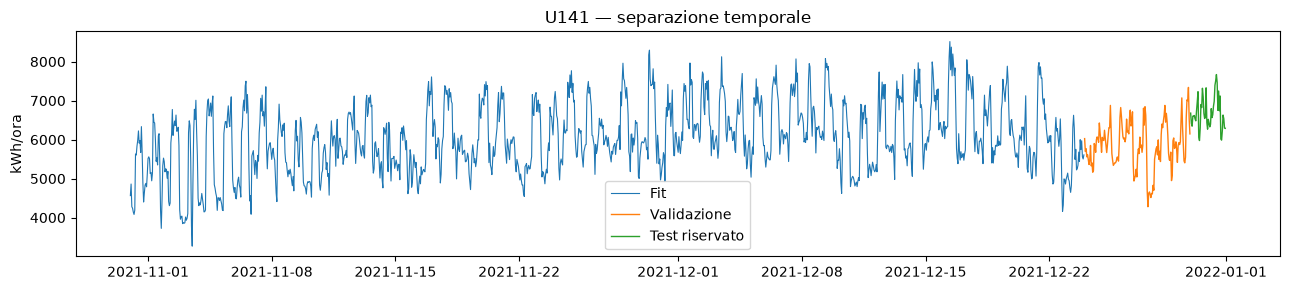

In [2]:
# --- Taglio del tratto iniziale non rappresentativo (stesso criterio dell'EDA) ---
def taglia_da_operativo(s, min_fermo_giorni=30, entro_frazione=0.5, soglia=0.05, verbose=True):
    """Rimuove SOLO il lungo fermo INIZIALE (>= min_fermo_giorni) se termina entro 'entro_frazione'
    della durata. Adattiva: se non c'e' un lungo fermo iniziale restituisce la serie invariata."""
    d = s.resample("D").sum(); med = d[d > 0].median()
    if not med or med != med: return s
    idle = (d < soglia * med); grp = (idle != idle.shift()).cumsum()
    tot = (d.index.max() - d.index.min()).days
    limite = d.index.min() + pd.offsets.Day(int(tot * entro_frazione))
    fine_taglio = None
    for _, g in d.groupby(grp):
        if idle.loc[g.index].iloc[0] and len(g) >= min_fermo_giorni and g.index.max() <= limite:
            fine_taglio = g.index.max()
    if fine_taglio is None:
        if verbose: print("taglia_da_operativo: nessun lungo fermo iniziale, serie invariata.")
        return s
    start = fine_taglio + pd.offsets.Day(1)
    if verbose: print(f"taglia_da_operativo: serie dal {start.date()} (rimossi ~{(start - s.index.min()).days} giorni).")
    return s.loc[start:]


def load_hourly(user):
    d = pd.read_csv(C24_DIR / f'{user}.csv')
    idx = pd.to_datetime(d['Time'])
    if idx.duplicated().any():
        raise ValueError('Timestamp duplicati nel CSV.')
    s = pd.Series(pd.to_numeric(d['Value'], errors='raise').to_numpy(), index=idx).sort_index()
    s = s.replace([np.inf, -np.inf], np.nan).clip(lower=0)
    s = taglia_da_operativo(s)
    return s.resample('h').sum(min_count=4).asfreq('h')

y = load_hourly(USER)
positive = y[y > 0]
if positive.empty:
    raise ValueError('Nessun consumo positivo disponibile.')
operating = y >= .05 * positive.median()
groups = (operating != operating.shift()).cumsum()
segments = [g for _, g in y.groupby(groups) if operating.loc[g.index].iloc[0]]
need = TRAIN_DAYS*24 + H
eligible = [g for g in segments if len(g) >= need]
if not eligible:
    raise ValueError(f'Nessun segmento operativo di {need} ore. Ridurre TRAIN_DAYS o cambiare utente.')
window = eligible[-1].iloc[-need:]
train, test = window.iloc[:-H].copy(), window.iloc[-H:].copy()
fit_end = len(train) - VAL_BLOCKS*H
assert fit_end >= LOOKBACK + H + TRAIN_STRIDE, 'Storico insufficiente per le finestre supervisionate.'
assert window.notna().all() and window.index.equals(pd.date_range(window.index[0], periods=need, freq='h'))
validation_origins = np.arange(fit_end, len(train), H, dtype=int)
fit_series = train.iloc[:fit_end]
validation_targets = np.stack([train.iloc[o:o+H].to_numpy() for o in validation_origins])
assert validation_origins[-1] + H == len(train)

display(pd.DataFrame([
    ['Fit per selezione', fit_series.index[0], fit_series.index[-1], len(fit_series)],
    ['Validazione', train.index[fit_end], train.index[-1], len(train)-fit_end],
    ['Train finale', train.index[0], train.index[-1], len(train)],
    ['Test finale', test.index[0], test.index[-1], len(test)],
], columns=['campione', 'inizio', 'fine', 'ore']))
fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(fit_series, label='Fit', lw=.8)
ax.plot(train.iloc[fit_end:], label='Validazione', lw=1)
ax.plot(test, label='Test riservato', lw=1)
ax.set_title(f'{USER} — separazione temporale')
ax.set_ylabel('kWh/ora')
ax.legend()
fig.tight_layout()
plt.show()

## 2. Ingressi e metriche comuni
Ogni esempio contiene gli ultimi 168 consumi orari, il calendario dello storico e il calendario delle 48 ore future. Sono noti in anticipo ora, giorno della settimana, weekend e date di Capodanno lunare; non usiamo meteo futuro osservato né flag di fermo ricavati dal futuro.

La normalizzazione è stimata sul solo fit durante la selezione e sul train completo durante il refit. Gli alberi ricevono il vettore dei consumi passati, statistiche delle ultime 24/168 ore e il calendario futuro; le reti ricevono la sequenza. Stessa informazione disponibile, rappresentazioni diverse.

**RMSE medio sui blocchi di validazione** sceglie configurazione ed epoca. Sul test riportiamo MAE, RMSE, sMAPE, MASE e R². MASE usa il naive giornaliero sul train come scala; R² può essere negativo ed è indefinito con test costante. Le previsioni non vengono troncate: eventuali valori negativi restano visibili, come nel confronto orario statistico.

In [3]:
CNY = ['2016-02-08', '2017-01-28', '2018-02-16', '2019-02-05',
       '2020-01-25', '2021-02-12', '2022-02-01']

def calendar(index):
    hour, week = index.hour.to_numpy(), (index.dayofweek*24+index.hour).to_numpy()
    day = index.dayofyear.to_numpy()
    holiday = np.zeros(len(index), dtype=np.float32)
    for date in CNY:
        holiday = np.maximum(holiday, ((index >= pd.Timestamp(date)-pd.offsets.Day(7)) &
                                      (index <= pd.Timestamp(date)+pd.offsets.Day(10))).astype(np.float32))
    return np.column_stack([np.sin(2*np.pi*hour/24), np.cos(2*np.pi*hour/24),
                            np.sin(2*np.pi*week/168), np.cos(2*np.pi*week/168),
                            np.sin(2*np.pi*day/366), np.cos(2*np.pi*day/366),
                            (index.dayofweek >= 5).astype(float), holiday]).astype(np.float32)

CAL_DIM = calendar(train.index[:1]).shape[1]

def fit_scaler(series):
    return StandardScaler().fit(series.to_numpy().reshape(-1, 1))

def inputs_at(series, origins, scaler):
    # series può terminare esattamente all'origine: i target futuri non sono richiesti.
    z = scaler.transform(series.to_numpy().reshape(-1, 1)).ravel().astype(np.float32)
    histories, futures = [], []
    for origin in origins:
        assert LOOKBACK <= origin <= len(series)
        past_idx = series.index[origin-LOOKBACK:origin]
        future_idx = pd.date_range(past_idx[-1]+pd.offsets.Hour(1), periods=H, freq='h')
        histories.append(np.column_stack([z[origin-LOOKBACK:origin], calendar(past_idx)]))
        futures.append(calendar(future_idx))
    return np.asarray(histories, dtype=np.float32), np.asarray(futures, dtype=np.float32)

def supervised(series, scaler):
    origins = np.arange(LOOKBACK, len(series)-H+1, TRAIN_STRIDE, dtype=int)
    x, future = inputs_at(series, origins, scaler)
    targets = np.stack([series.iloc[o:o+H].to_numpy() for o in origins])
    targets = ((targets-scaler.mean_[0])/scaler.scale_[0]).astype(np.float32)
    assert (origins+H <= len(series)).all()
    return x, future, targets, origins

def tree_features(history, future):
    values = history[:, :, 0]
    summary = np.column_stack([stat(values[:, -width:], axis=1)
                               for width in (24, 168) for stat in (np.mean, np.std, np.min, np.max)])
    data = np.concatenate([values, summary, history[:, -1, 1:], future.reshape(len(future), -1)], axis=1)
    # Stessi nomi e stesso ordine in fit/predict: LightGBM registra i nomi anche
    # quando il fit riceve un ndarray; un DataFrame evita il warning sklearn.
    names = ([f'load_lag_{lag}' for lag in range(values.shape[1], 0, -1)]
             + [f'{stat}_{width}h' for width in (24, 168) for stat in ('mean', 'std', 'min', 'max')]
             + [f'calendar_last_{k}' for k in range(history.shape[2]-1)]
             + [f'calendar_h{h+1}_{k}' for h in range(future.shape[1]) for k in range(future.shape[2])])
    return pd.DataFrame(data, columns=names)

def undo_scale(prediction, scaler):
    return np.asarray(prediction)*scaler.scale_[0]+scaler.mean_[0]

def validation_rmse(prediction):
    prediction = np.asarray(prediction)
    if prediction.shape != validation_targets.shape or not np.isfinite(prediction).all():
        raise ValueError('Previsioni di validazione non valide.')
    return float(np.sqrt(np.mean((prediction-validation_targets)**2, axis=1)).mean())

def scores(actual, predicted, history):
    a, p = np.asarray(actual, float), np.asarray(predicted, float)
    if a.shape != p.shape or not np.isfinite(p).all():
        raise ValueError('Previsione non valida: dimensioni o valori non finiti.')
    error, denom = a-p, np.abs(a)+np.abs(p)
    scale = history.diff(24).abs().dropna().mean()
    return {'MAE': mean_absolute_error(a, p), 'RMSE': np.sqrt(mean_squared_error(a, p)),
            'sMAPE %': 100*np.divide(2*np.abs(error), denom, out=np.zeros_like(error), where=denom != 0).mean(),
            'MASE': np.abs(error).mean()/scale if scale > 0 else np.nan,
            'R²': r2_score(a, p) if len(a) > 1 and np.var(a) > 0 else np.nan}

selection_scaler = fit_scaler(fit_series)
X_fit, F_fit, Y_fit, fit_origins = supervised(fit_series, selection_scaler)
X_val, F_val = inputs_at(train, validation_origins, selection_scaler)
Y_val = ((validation_targets-selection_scaler.mean_[0])/selection_scaler.scale_[0]).astype(np.float32)
print(f'{len(Y_fit)} esempi di fit | lookback {LOOKBACK}h | output {H}h | {len(Y_val)} blocchi di validazione')
# Verifica causale: modificare il futuro non modifica gli ingressi all'origine.
_probe = train.copy()
_probe.iloc[fit_end:] = -999999
assert np.array_equal(inputs_at(_probe, [fit_end], selection_scaler)[0], X_val[:1])
assert np.array_equal(inputs_at(_probe, [fit_end], selection_scaler)[1], F_val[:1])
del _probe

181 esempi di fit | lookback 168h | output 48h | 3 blocchi di validazione


## 3. XGBoost e LightGBM: API scikit-learn
Usiamo `MultiOutputRegressor`: un regressore per ciascun orizzonte, addestrato sulle stesse origini. Non è una previsione ricorsiva e non utilizza i consumi del test come lag. Le 48 regressioni vengono eseguite in sequenza; i singoli alberi sfruttano i thread CPU, evitando due livelli di parallelismo concorrenti.

La griglia è volutamente piccola e modificabile. In questa prima versione non si applica early stopping agli alberi: `n_estimators` è un parametro selezionato sulla validazione.

**Isolamento OpenMP:** XGBoost e LightGBM sono eseguiti ciascuno in un processo separato tramite `eweld_tree_worker.py`, da mantenere accanto al notebook. Il processo usa `sys.executable`, quindi lo stesso venv del kernel, e al massimo due thread. Non carica PyTorch né l’altro backend ad alberi. Il kernel riceve solo previsioni e risultati della selezione; i pesi degli alberi non sono conservati. Un crash nativo del processo viene riportato come errore senza arrestare il kernel. Non si usa `KMP_DUPLICATE_LIB_OK`.

In [4]:
def run_tree(name):
    # Nessuna libreria XGBoost/LightGBM viene caricata nel kernel PyTorch.
    import subprocess
    import tempfile
    start_all = perf_counter()
    final_scaler = fit_scaler(train)
    x, f, target, _ = supervised(train, final_scaler)
    xp, fp = inputs_at(train, [len(train)], final_scaler)
    xfit = tree_features(X_fit, F_fit)
    request = dict(name=name, grid=TREE_GRID[name], threads=min(CPU_THREADS, 2), seed=SEED,
                   columns=xfit.columns.tolist(), selection_scale=float(selection_scaler.scale_[0]),
                   selection_mean=float(selection_scaler.mean_[0]),
                   final_scale=float(final_scaler.scale_[0]), final_mean=float(final_scaler.mean_[0]))
    if not TREE_WORKER_PATH.is_file():
        raise FileNotFoundError(f'Helper necessario accanto al notebook: {TREE_WORKER_PATH}')
    with tempfile.TemporaryDirectory(prefix='eweld_tree_') as temp:
        work = Path(temp)
        req, arrays, result = work/'request.json', work/'arrays.npz', work/'result.json'
        req.write_text(json.dumps(request))
        np.savez(arrays, xfit=xfit.to_numpy(), xval=tree_features(X_val, F_val).to_numpy(), yfit=Y_fit,
                 validation_targets=validation_targets, xfinal=tree_features(x, f).to_numpy(),
                 yfinal=target, xpredict=tree_features(xp, fp).to_numpy())
        env = os.environ.copy()
        # Limiti impostati prima degli import, non su runtime OpenMP già inizializzati.
        for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
            env[key] = str(request['threads'])
        env.pop('KMP_DUPLICATE_LIB_OK', None)
        print(f'{name}: processo dedicato | Python {sys.executable}', flush=True)
        tail = []
        process = subprocess.Popen([sys.executable, '-u', str(TREE_WORKER_PATH), str(req), str(arrays), str(result)],
                                   stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
        try:
            for line in process.stdout:
                print(line, end='', flush=True)
                tail = (tail + [line])[-20:]
            returncode = process.wait()
        except BaseException:
            process.terminate()
            try:
                process.wait(timeout=5)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
            raise
        finally:
            process.stdout.close()
        if returncode != 0:
            raise RuntimeError(f'{name}: processo terminato con codice {returncode}; kernel preservato. ' + ''.join(tail))
        output = json.loads(result.read_text())
    search_rows.extend(output['search'])
    if 'error' in output:
        raise RuntimeError(output['error'])
    pred = np.asarray(output['prediction'])
    if pred.shape != (H,) or not np.isfinite(pred).all():
        raise ValueError('Output del processo non valido.')
    predictions[name] = pd.Series(pred, index=test.index)
    selection[name] = output['selection']
    selection[name]['secondi'] = perf_counter()-start_all


## 4. LSTM, GRU e ConvLSTM-MDN in PyTorch
**LSTM/GRU:** encoder ricorrente sullo storico; testa condivisa che usa contesto, calendario futuro e posizione dell’orizzonte per produrre tutti i valori.

**ConvLSTM-MDN:** implementazione compatta ispirata alla famiglia descritta nel paper, non una replica esatta. Lo storico è rappresentato come sequenza di giorni, ciascuno una griglia `1 × 24 ore`; una vera cella ConvLSTM usa convoluzioni nei gate. La testa MDN produce pesi, medie e deviazioni di una miscela gaussiana per ciascuna ora futura. Si addestra con negative log-likelihood e si seleziona usando RMSE della media predittiva, così il criterio resta comune.

Le distribuzioni sono marginali per orizzonte: non costituiscono una distribuzione congiunta delle 48 ore. Le bande sono grezze, non calibrate; le componenti gaussiane possono assegnare probabilità a consumi negativi.

In [5]:
if torch is not None:
    class RecurrentForecaster(nn.Module):
        def __init__(self, kind, cfg):
            super().__init__()
            recurrent = nn.LSTM if kind == 'LSTM' else nn.GRU
            self.encoder = recurrent(1+CAL_DIM, cfg['hidden'], batch_first=True)
            self.head = nn.Sequential(nn.Linear(cfg['hidden']+CAL_DIM+1, cfg['hidden']), nn.ReLU(),
                                      nn.Dropout(cfg['dropout']), nn.Linear(cfg['hidden'], 1))

        def forward(self, history, future):
            _, state = self.encoder(history)
            hidden = state[0] if isinstance(state, tuple) else state
            context = hidden[-1].unsqueeze(1).expand(-1, H, -1)
            horizon = torch.linspace(1/H, 1, H, device=history.device, dtype=history.dtype)
            horizon = horizon.view(1, H, 1).expand(history.shape[0], -1, -1)
            return self.head(torch.cat([context, future, horizon], dim=-1)).squeeze(-1)

    class ConvLSTMCell(nn.Module):
        def __init__(self, channels, hidden):
            super().__init__()
            self.hidden = hidden
            self.gates = nn.Conv2d(channels+hidden, 4*hidden, kernel_size=(1, 3), padding=(0, 1))

        def forward(self, x, h, c):
            i, f, o, g = self.gates(torch.cat([x, h], dim=1)).chunk(4, dim=1)
            c = torch.sigmoid(f)*c + torch.sigmoid(i)*torch.tanh(g)
            h = torch.sigmoid(o)*torch.tanh(c)
            return h, c

    class ConvLSTMMDN(nn.Module):
        def __init__(self, cfg):
            super().__init__()
            self.hidden, self.components = cfg['hidden'], cfg['components']
            self.cell = ConvLSTMCell(1+CAL_DIM, self.hidden)
            self.head = nn.Sequential(nn.Linear(self.hidden*24+CAL_DIM+1, 32), nn.ReLU(),
                                      nn.Dropout(cfg['dropout']), nn.Linear(32, 3*self.components))

        def forward(self, history, future):
            batch = history.shape[0]
            days = history.reshape(batch, LOOKBACK//24, 24, 1+CAL_DIM).permute(0, 1, 3, 2).unsqueeze(3)
            h = history.new_zeros(batch, self.hidden, 1, 24)
            c = torch.zeros_like(h)
            for day in days.unbind(dim=1):
                h, c = self.cell(day, h, c)
            context = h.flatten(1).unsqueeze(1).expand(-1, H, -1)
            horizon = torch.linspace(1/H, 1, H, device=history.device, dtype=history.dtype)
            horizon = horizon.view(1, H, 1).expand(batch, -1, -1)
            logits, mean, raw_sigma = self.head(torch.cat([context, future, horizon], dim=-1)).chunk(3, dim=-1)
            sigma = nn.functional.softplus(raw_sigma)+.01
            return logits, mean, sigma

    def mdn_loss(output, target):
        logits, mean, sigma = output
        log_prob = -.5*((target.unsqueeze(-1)-mean)/sigma)**2 - torch.log(sigma) - .5*np.log(2*np.pi)
        return -torch.logsumexp(torch.log_softmax(logits, dim=-1)+log_prob, dim=-1).mean()

    def point_output(output):
        if isinstance(output, tuple):
            logits, mean, _ = output
            return (torch.softmax(logits, dim=-1)*mean).sum(dim=-1)
        return output

## 5. Temporal Fusion Transformer originale
Usiamo `TemporalFusionTransformer` di PyTorch Forecasting, con variable selection, encoder/decoder ricorrenti, gating e attenzione. Il target è una variabile **sconosciuta nel futuro**, mentre le colonne di calendario sono note. Per l’inferenza i target futuri sono segnaposto zero standardizzati: il decoder non li riceve come regressori.

La testa è puntuale e si addestra con MSE, per rendere il confronto con RMSE diretto. La libreria supporta anche quantili, ma qui la previsione probabilistica è esplorata separatamente con MDN. Usiamo un ciclo PyTorch esplicito anche per TFT per avere identiche regole di selezione dell’epoca, senza salvataggi automatici o dipendenze da Trainer/Jupyter multiprocessing.

In [6]:
if torch is not None:
    class TFTAdapter(nn.Module):
        def __init__(self, dataset, cfg):
            super().__init__()
            pf = optional['pytorch_forecasting']
            from pytorch_forecasting.metrics import RMSE
            self.network = pf.TemporalFusionTransformer.from_dataset(
                dataset, hidden_size=cfg['hidden'], attention_head_size=cfg['heads'],
                hidden_continuous_size=cfg['hidden'], dropout=cfg['dropout'],
                output_size=1, loss=RMSE(), learning_rate=cfg['lr'],
                optimizer='adam', log_interval=-1, mask_bias=-1e4)

        def forward(self, batch):
            return self.network(batch).prediction.squeeze(-1)

def tft_frame(series, scaler):
    frame = pd.DataFrame({'time_idx': np.arange(len(series), dtype=np.int64), 'plant': USER,
                          'target': scaler.transform(series.to_numpy().reshape(-1, 1)).ravel().astype(np.float32)})
    cal = calendar(series.index)
    for k in range(CAL_DIM):
        frame[f'cal_{k}'] = cal[:, k]
    return frame

def tft_training(series, scaler):
    pf = optional['pytorch_forecasting']
    frame = tft_frame(series, scaler)
    dataset = pf.TimeSeriesDataSet(
        frame, time_idx='time_idx', target='target', group_ids=['plant'],
        min_encoder_length=LOOKBACK, max_encoder_length=LOOKBACK,
        min_prediction_length=H, max_prediction_length=H,
        static_categoricals=['plant'],
        time_varying_known_reals=[f'cal_{k}' for k in range(CAL_DIM)],
        time_varying_unknown_reals=['target'], target_normalizer=None,
        add_relative_time_idx=True, add_target_scales=False, add_encoder_length=False)
    origins = np.arange(LOOKBACK, len(series)-H+1, TRAIN_STRIDE)
    dataset = dataset.filter(lambda index: index.time_idx_first_prediction.isin(origins))
    return dataset

def tft_validation(training_dataset, scaler):
    pf = optional['pytorch_forecasting']
    dataset = pf.TimeSeriesDataSet.from_dataset(training_dataset, tft_frame(train, scaler),
                                               min_prediction_idx=fit_end, stop_randomization=True)
    dataset = dataset.filter(lambda index: index.time_idx_first_prediction.isin(validation_origins))
    assert len(dataset) == VAL_BLOCKS
    return dataset

def tft_future(training_dataset, scaler):
    pf = optional['pytorch_forecasting']
    future_idx = pd.date_range(train.index[-1]+pd.offsets.Hour(1), periods=H, freq='h')
    # Nessun valore reale del test: riempiamo con la media train (zero dopo scaling).
    placeholder = pd.Series(np.repeat(scaler.mean_[0], H), index=future_idx)
    frame = tft_frame(pd.concat([train, placeholder]), scaler)
    return pf.TimeSeriesDataSet.from_dataset(training_dataset, frame, predict=True, stop_randomization=True)

## 6. Training, selezione e refit
Per ogni rete confrontiamo le configurazioni in `NET_GRID`. Si controlla a ogni epoca il RMSE medio sui blocchi di validazione e si interrompe dopo `PATIENCE` epoche senza miglioramenti. Il refit finale usa i parametri e il numero di epoche selezionati, senza leggere il test.

In caso di errore MPS non viene cambiato silenziosamente il dispositivo: il problema compare nel log. Si può scegliere CPU e rieseguire. Tempi e risultati dipendono da ambiente, dataset e configurazione; non è garantita riproducibilità bit per bit su MPS.

**Stabilità su questo Mac:** i log hanno mostrato SIGABRT in Metal/MPS all’avvio di TFT. `MODEL_DEVICES` forza TFT e ConvLSTM-MDN sulla CPU; LSTM/GRU mantengono il dispositivo automatico. Un crash nativo non è recuperabile dal `try/except` Python né dal fallback MPS. Batch ridotto a 16 e pesi non conservati dopo la previsione (`KEEP_MODELS=False`).

In [7]:
def seed_torch():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

def move(value, device):
    if torch.is_tensor(value):
        return value.to(device=device, dtype=torch.float32 if value.is_floating_point() else None)
    if isinstance(value, dict):
        return {k: move(v, device) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return type(value)(move(v, device) if v is not None else None for v in value)
    return value

def ordinary_loader(history, future, target, shuffle=False):
    dataset = TensorDataset(*(torch.from_numpy(np.asarray(a, dtype=np.float32)) for a in (history, future, target)))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0,
                      generator=torch.Generator().manual_seed(SEED))

def unpack_forward(model, batch, is_tft):
    if is_tft:
        x, y = move(batch, DEVICE)
        output = model(x)
        return output, y[0]
    x, f, y = move(batch, DEVICE)
    return model(x, f), y

def evaluate_network(model, loader, is_tft):
    model.eval()
    results = []
    with torch.no_grad():
        for batch in loader:
            output, _ = unpack_forward(model, batch, is_tft)
            results.append(point_output(output).detach().cpu().numpy())
    pred = np.concatenate(results)
    if not np.isfinite(pred).all():
        raise ValueError('Output della rete non finito.')
    return pred

def train_network(model, train_loader, cfg, epochs, val_loader=None, scaler=None, is_tft=False):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    best_score, best_epoch, stale = np.inf, None, 0
    history = []
    for epoch in range(1, epochs+1):
        model.train()
        total, count = 0., 0
        for batch in train_loader:
            optimizer.zero_grad(set_to_none=True)
            output, target = unpack_forward(model, batch, is_tft)
            loss = mdn_loss(output, target) if isinstance(output, tuple) else nn.functional.mse_loss(output, target)
            if not torch.isfinite(loss):
                raise ValueError('Loss non finita.')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimizer.step()
            total += loss.item()*len(target)
            count += len(target)
        score = np.nan
        if val_loader is not None:
            pred = undo_scale(evaluate_network(model, val_loader, is_tft), scaler)
            score = validation_rmse(pred)
            if score < best_score:
                best_score, best_epoch, stale = score, epoch, 0
            else:
                stale += 1
        history.append(dict(epoca=epoch, loss_train=total/count, RMSE_val=score))
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            val_label = f'RMSE val={score:.3f}' if val_loader is not None else 'refit: validazione non eseguita'
            print(f'  epoca {epoch}/{epochs} | loss={total/count:.4f} | {val_label}', flush=True)
        if val_loader is not None and stale >= PATIENCE:
            break
    # Nel tuning non serve ripristinare i pesi migliori: il modello sarà rifatto da zero.
    return best_score, best_epoch, pd.DataFrame(history)

def make_network(name, cfg, dataset=None):
    if name in ('LSTM', 'GRU'):
        return RecurrentForecaster(name, cfg)
    if name == 'ConvLSTM-MDN':
        return ConvLSTMMDN(cfg)
    return TFTAdapter(dataset, cfg)

def release_device():
    gc.collect()
    if torch is not None and DEVICE == 'mps':
        torch.mps.empty_cache()

def _run_network_on_device(name):
    start_all = perf_counter()
    is_tft = name == 'TFT'
    dataset = tft_training(fit_series, selection_scaler) if is_tft else None
    if is_tft:
        train_loader = dataset.to_dataloader(train=True, batch_size=BATCH_SIZE, num_workers=0, drop_last=False)
        val_loader = tft_validation(dataset, selection_scaler).to_dataloader(train=False, batch_size=BATCH_SIZE, num_workers=0)
    else:
        train_loader = ordinary_loader(X_fit, F_fit, Y_fit, shuffle=True)
        val_loader = ordinary_loader(X_val, F_val, Y_val)
    candidates = []
    for cid, cfg in enumerate(NET_GRID[name]):
        start = perf_counter()
        model = None
        try:
            seed_torch()
            model = make_network(name, cfg, dataset)
            score, best_epoch, curve = train_network(model, train_loader, cfg, MAX_EPOCHS,
                                                      val_loader, selection_scaler, is_tft)
            if not np.isfinite(score) or best_epoch is None:
                raise ValueError('Nessuna epoca valida.')
            histories[(name, cid)] = curve
            candidates.append((score, cid, cfg, best_epoch))
            state = 'OK'
        except Exception as exc:
            score, best_epoch, state = np.nan, None, f'{type(exc).__name__}: {exc}'
        search_rows.append(dict(modello=name, candidato=cid, RMSE_val=score, epoca=best_epoch,
                                parametri=json.dumps(cfg), secondi=perf_counter()-start, stato=state))
        print(f'{name} candidato {cid+1}: RMSE val={score:.3f} | epoca={best_epoch} | {state}', flush=True)
        del model
        release_device()
    if not candidates:
        raise RuntimeError('Nessuna configurazione valida: consultare ricerca_parametri. Se errore MPS, provare DEVICE_PREFERENCE="cpu".')
    score, cid, cfg, best_epoch = min(candidates, key=lambda row: (row[0], row[1]))
    scaler = fit_scaler(train)
    seed_torch()
    if is_tft:
        final_dataset = tft_training(train, scaler)
        final_loader = final_dataset.to_dataloader(train=True, batch_size=BATCH_SIZE, num_workers=0, drop_last=False)
        predict_loader = tft_future(final_dataset, scaler).to_dataloader(train=False, batch_size=1, num_workers=0)
    else:
        final_dataset = None
        x, f, target, _ = supervised(train, scaler)
        final_loader = ordinary_loader(x, f, target, shuffle=True)
        xp, fp = inputs_at(train, [len(train)], scaler)
        predict_loader = ordinary_loader(xp, fp, np.zeros((1, H), dtype=np.float32))
    model = make_network(name, cfg, final_dataset)
    print(f'{name}: refit su tutto il train per {best_epoch} epoche ({DEVICE}).', flush=True)
    train_network(model, final_loader, cfg, best_epoch, is_tft=is_tft)
    pred = undo_scale(evaluate_network(model, predict_loader, is_tft), scaler)[0]
    if name == 'ConvLSTM-MDN':
        model.eval()
        with torch.no_grad():
            out = model(torch.from_numpy(xp).to(DEVICE), torch.from_numpy(fp).to(DEVICE))
        pi = torch.softmax(out[0], dim=-1)[0].cpu().numpy()
        mu = undo_scale(out[1][0].cpu().numpy(), scaler)
        sigma = out[2][0].cpu().numpy()*scaler.scale_[0]
        intervals[name] = dict(pi=pi, mu=mu, sigma=sigma)
    # Archiviazione su CPU: non accumulare i modelli nella memoria GPU.
    if KEEP_MODELS:
        models[name] = (model.cpu(), scaler)
    predictions[name] = pd.Series(pred, index=test.index)
    selection[name] = dict(parametri=cfg, RMSE_val=score, epoche=best_epoch, device=DEVICE, secondi=perf_counter()-start_all)
    release_device()

def run_network(name):
    # Il dispositivo selezionato è usato anche da batch, loss e inferenza.
    # SIGABRT di Metal non è intercettabile: TFT resta su CPU dall'inizio.
    global DEVICE
    previous = DEVICE
    DEVICE = MODEL_DEVICES.get(name, previous)
    try:
        print(f'{name}: dispositivo {DEVICE}, batch {BATCH_SIZE}', flush=True)
        return _run_network_on_device(name)
    finally:
        release_device()
        DEVICE = previous


## 7. Esecuzione dei sei modelli
Questa cella esegue ricerca, refit e previsione. Può richiedere diversi minuti o più, soprattutto per TFT. Per una prima prova cambiare `RUN_MODELS` in `['XGBoost', 'LightGBM', 'LSTM']`; gli altri restano implementati e si possono aggiungere dopo. Non eseguire contemporaneamente più notebook di training sulla GPU.

Ogni modello fallito o privo di dipendenze resta nel registro con la causa. Le classifiche contengono soltanto previsioni valide: l’assenza di un modello non equivale a una prestazione peggiore.

`CHECKPOINT_RESULTS=True` salva automaticamente snapshot JSON in una nuova cartella `risultati_modelli_avanzati/*_parziali`, prima e dopo ciascun modello. Contengono previsioni, parametri, ricerca e stato: in caso di arresto i risultati precedenti sono recuperabili anche senza salvare il notebook. Non sono checkpoint di training e non riprendono un’epoca interrotta. Per leggere uno snapshot: `saved = json.loads(Path("percorso/snapshot_04.json").read_text())`; `pd.DataFrame(saved["predictions"], index=pd.to_datetime(saved["test_index"]))` ricostruisce le previsioni completate.

In [8]:
# Rieseguire questa cella azzera i risultati del precedente run.
search_rows, histories, selection, models, predictions, model_status, intervals = [], {}, {}, {}, {}, {}, {}
checkpoint_dir = None
if CHECKPOINT_RESULTS:
    stamp = pd.Timestamp.now().strftime('%Y%m%d_%H%M%S_%f')
    checkpoint_dir = ROOT/'risultati_modelli_avanzati'/f'{USER}_{stamp}_parziali'
    checkpoint_dir.mkdir(parents=True, exist_ok=False)
    print('Risultati intermedi:', checkpoint_dir, flush=True)

def save_progress():
    if checkpoint_dir is None:
        return
    # Un file autonomo per ogni stato: un arresto successivo non tocca gli snapshot precedenti.
    snapshot = dict(user=USER, horizon=H, train_start=str(train.index[0]),
                    train_end=str(train.index[-1]), test_index=[str(t) for t in test.index],
                    predictions={k: v.tolist() for k, v in predictions.items()},
                    selection=selection, states=model_status, search=search_rows, versions=versions,
                    intervals={k: {q: a.tolist() for q, a in v.items()} for k, v in intervals.items()},
                    configuration=dict(seed=SEED, lookback=LOOKBACK, train_days=TRAIN_DAYS,
                        val_blocks=VAL_BLOCKS, stride=TRAIN_STRIDE, batch_size=BATCH_SIZE,
                        max_epochs=MAX_EPOCHS, patience=PATIENCE, model_devices=MODEL_DEVICES,
                        tree_grid=TREE_GRID, net_grid=NET_GRID))
    path = checkpoint_dir/f'snapshot_{len(model_status):02d}.json'
    temp = path.with_suffix('.tmp')
    temp.write_text(json.dumps(snapshot, indent=2, ensure_ascii=False), encoding='utf-8')
    temp.replace(path)

required = {'XGBoost': ['xgboost'], 'LightGBM': ['lightgbm'], 'LSTM': ['torch'],
            'GRU': ['torch'], 'TFT': ['torch', 'pytorch_forecasting'], 'ConvLSTM-MDN': ['torch']}
for name in RUN_MODELS:
    missing = [package for package in required[name] if package not in optional]
    if missing:
        model_status[name] = 'NON ESEGUITO: ' + ' | '.join(f'{p}: {import_errors.get(p, "non disponibile")}' for p in missing)
        print(name, model_status[name], flush=True)
        save_progress()
        continue
    model_status[name] = 'IN CORSO'
    save_progress()
    print(f'\n--- {name} ---', flush=True)
    try:
        if name in TREE_GRID:
            run_tree(name)
        else:
            run_network(name)
        model_status[name] = 'OK'
    except Exception as exc:
        model_status[name] = f'ERRORE: {type(exc).__name__}: {exc}'
        print(name, model_status[name], flush=True)
        release_device()

    save_progress()
    release_device()

ricerca_parametri = pd.DataFrame(search_rows)
display(pd.Series(model_status, name='stato').to_frame())
if not ricerca_parametri.empty:
    display(ricerca_parametri.sort_values(['modello', 'RMSE_val']))
if selection:
    display(pd.DataFrame(selection).T)
else:
    print('Nessun modello avanzato completato: verificare dipendenze e log prima di interpretare il confronto.')

Risultati intermedi: /Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/datasets/risultati_modelli_avanzati/U141_20261001_205134_702386_parziali

--- XGBoost ---
XGBoost: processo dedicato | Python /Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/.venv_eweld/bin/python
XGBoost candidato 1: RMSE val=589.5376118764265 | OK
XGBoost candidato 2: RMSE val=572.2860001392422 | OK

--- LightGBM ---
LightGBM: processo dedicato | Python /Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/.venv_eweld/bin/python
LightGBM candidato 1: RMSE val=594.4855215003637 | OK
LightGBM candidato 2: RMSE val=607.7214183590164 | OK

--- LSTM ---
LSTM: dispositivo mps, batch 16
  epoca 1/15 | loss=0.8932 | RMSE val=613.221
  epoca 5/15 | loss=0.7965 | RMSE val=635.280
LSTM candidato 1: RMSE val=613.221 | epoca=1 | OK
  epoca 1/15 | loss=0.8469 | RMSE val=632.234
  epoca 5/15 | loss=0.7390 | RMSE val=649.069
LSTM candidato 2: RMSE val=632.234 | epoca=1 

/Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/.venv_eweld/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/.venv_eweld/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


  epoca 1/15 | loss=0.8839 | RMSE val=762.850
  epoca 5/15 | loss=0.6433 | RMSE val=905.824
TFT candidato 1: RMSE val=762.850 | epoca=1 | OK
  epoca 1/15 | loss=0.9744 | RMSE val=826.614
  epoca 5/15 | loss=0.6225 | RMSE val=891.360
TFT candidato 2: RMSE val=723.476 | epoca=2 | OK
TFT: refit su tutto il train per 2 epoche (cpu).


/Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/.venv_eweld/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/.venv_eweld/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


  epoca 1/2 | loss=0.9872 | refit: validazione non eseguita
  epoca 2/2 | loss=0.8298 | refit: validazione non eseguita

--- ConvLSTM-MDN ---
ConvLSTM-MDN: dispositivo cpu, batch 16
  epoca 1/15 | loss=1.3927 | RMSE val=619.315
  epoca 5/15 | loss=1.2449 | RMSE val=585.069
  epoca 10/15 | loss=1.1705 | RMSE val=587.033
ConvLSTM-MDN candidato 1: RMSE val=577.775 | epoca=6 | OK
  epoca 1/15 | loss=1.4130 | RMSE val=602.518
  epoca 5/15 | loss=1.2545 | RMSE val=597.190
ConvLSTM-MDN candidato 2: RMSE val=597.190 | epoca=5 | OK
ConvLSTM-MDN: refit su tutto il train per 6 epoche (cpu).
  epoca 1/6 | loss=1.4007 | refit: validazione non eseguita
  epoca 5/6 | loss=1.2467 | refit: validazione non eseguita
  epoca 6/6 | loss=1.2274 | refit: validazione non eseguita


,stato
XGBoost,OK
LightGBM,OK
LSTM,OK
GRU,OK
TFT,OK
ConvLSTM-MDN,OK


,modello,candidato,RMSE_val,epoca,parametri,secondi,stato
10,ConvLSTM-MDN,0,577.774826,6.0,"{""hidden"": 4, ""components"": 3, ""dropout"": 0.1,...",0.500409,OK
11,ConvLSTM-MDN,1,597.190338,5.0,"{""hidden"": 8, ""components"": 3, ""dropout"": 0.1,...",0.502104,OK
7,GRU,1,589.493875,1.0,"{""hidden"": 32, ""dropout"": 0.1, ""lr"": 0.001}",2.493996,OK
6,GRU,0,640.621749,8.0,"{""hidden"": 16, ""dropout"": 0.1, ""lr"": 0.001}",5.913286,OK
4,LSTM,0,613.220501,1.0,"{""hidden"": 16, ""dropout"": 0.1, ""lr"": 0.001}",0.864251,OK
5,LSTM,1,632.234236,1.0,"{""hidden"": 32, ""dropout"": 0.1, ""lr"": 0.001}",0.605589,OK
2,LightGBM,0,594.485522,NaN,"{""n_estimators"": 100, ""num_leaves"": 7, ""learni...",2.946792,OK
3,LightGBM,1,607.721418,NaN,"{""n_estimators"": 200, ""num_leaves"": 15, ""learn...",6.878142,OK
9,TFT,1,723.476334,2.0,"{""hidden"": 16, ""heads"": 2, ""dropout"": 0.1, ""lr...",2.630753,OK
8,TFT,0,762.849589,1.0,"{""hidden"": 8, ""heads"": 2, ""dropout"": 0.1, ""lr""...",1.710954,OK


,parametri,RMSE_val,epoche,device,secondi
XGBoost,"{'n_estimators': 200, 'max_depth': 4, 'learnin...",572.286,None,cpu / processo isolato,48.90408
LightGBM,"{'n_estimators': 100, 'num_leaves': 7, 'learni...",594.485522,None,cpu / processo isolato,14.450232
LSTM,"{'hidden': 16, 'dropout': 0.1, 'lr': 0.001}",613.220501,1,mps,1.886383
GRU,"{'hidden': 32, 'dropout': 0.1, 'lr': 0.001}",589.493875,1,mps,9.215313
TFT,"{'hidden': 16, 'heads': 2, 'dropout': 0.1, 'lr...",723.476334,2,cpu,5.563957
ConvLSTM-MDN,"{'hidden': 4, 'components': 3, 'dropout': 0.1,...",577.774826,6,cpu,1.483937


## 8. Confronto side-by-side con baseline
Aggiungiamo persistenza, naive giornaliero/settimanale e media mobile. **Non riaddestriamo né retuniamo ARIMA/SARIMA**: per il confronto con il precedente notebook verificare che utente, date, durata train e orizzonte coincidano. Il nuovo notebook mostra esplicitamente questi estremi nella sezione 1.

La scelta del modello resta basata sulla validazione. Ordinare la tabella del test serve a descrivere questo esperimento; scegliere ripetutamente configurazioni guardando questa tabella contaminerebbe il test.

,RMSE validazione,RMSE test,MAE test,MASE,R²
Modello,,,,,
TFT,723.48,638.07,522.22,0.854,-1.385
Persistenza,—,678.71,560.88,0.917,-1.698
Media mobile 24h,—,693.69,576.52,0.942,-1.819
GRU,589.49,739.50,634.10,1.036,-2.203
XGBoost,572.29,746.34,649.05,1.061,-2.263
LSTM,613.22,748.18,630.12,1.030,-2.279
ConvLSTM-MDN,577.77,758.73,680.32,1.112,-2.372
LightGBM,594.49,808.62,699.04,1.143,-2.830
Naive 24h,—,911.28,780.15,1.275,-3.864


,Reale,Persistenza,Naive 24h,Naive 168h,Media mobile 24h,XGBoost,LightGBM,LSTM,GRU,TFT,ConvLSTM-MDN
Time,,,,,,,,,,,
2021-12-30 00:00:00,6679.7500,6146.9081,5971.1252,5059.2515,6128.139621,6146.931152,6228.458831,6061.235723,6059.468956,6186.172860,5879.375877
2021-12-30 01:00:00,6416.0757,6146.9081,6042.5370,5141.6497,6128.139621,6159.921875,6303.203036,6068.483025,6063.823461,6189.919201,5865.840363
2021-12-30 02:00:00,6344.6638,6146.9081,5773.3694,4987.8396,6128.139621,6267.844238,6556.020943,6076.297480,6069.880258,6188.630352,5863.089399
2021-12-30 03:00:00,6602.8450,6146.9081,5800.8355,4943.8939,6128.139621,6471.102051,6383.872562,6083.049425,6079.446970,6186.005020,5870.550902
2021-12-30 04:00:00,6597.3517,6146.9081,5943.6591,4762.6178,6128.139621,6397.137695,6277.314090,6083.730505,6094.429663,6183.516349,5887.492172
2021-12-30 05:00:00,6619.3246,6146.9081,5745.9034,4647.2603,6128.139621,6260.256836,6364.465552,6084.448508,6109.659222,6182.602511,5913.650381
2021-12-30 06:00:00,6531.4332,6146.9081,5416.3105,4823.0432,6128.139621,6031.782227,6099.074614,6083.481189,6125.935550,6186.405937,5951.479384
2021-12-30 07:00:00,6481.9944,6146.9081,5850.2744,5388.8443,6128.139621,5907.323730,5684.001775,6074.741141,6138.152882,6195.505394,6002.211257
2021-12-30 08:00:00,6740.1754,6146.9081,5921.6863,6317.1977,6128.139621,5889.473633,6203.196705,6063.811422,6148.035986,6205.891969,6057.962737


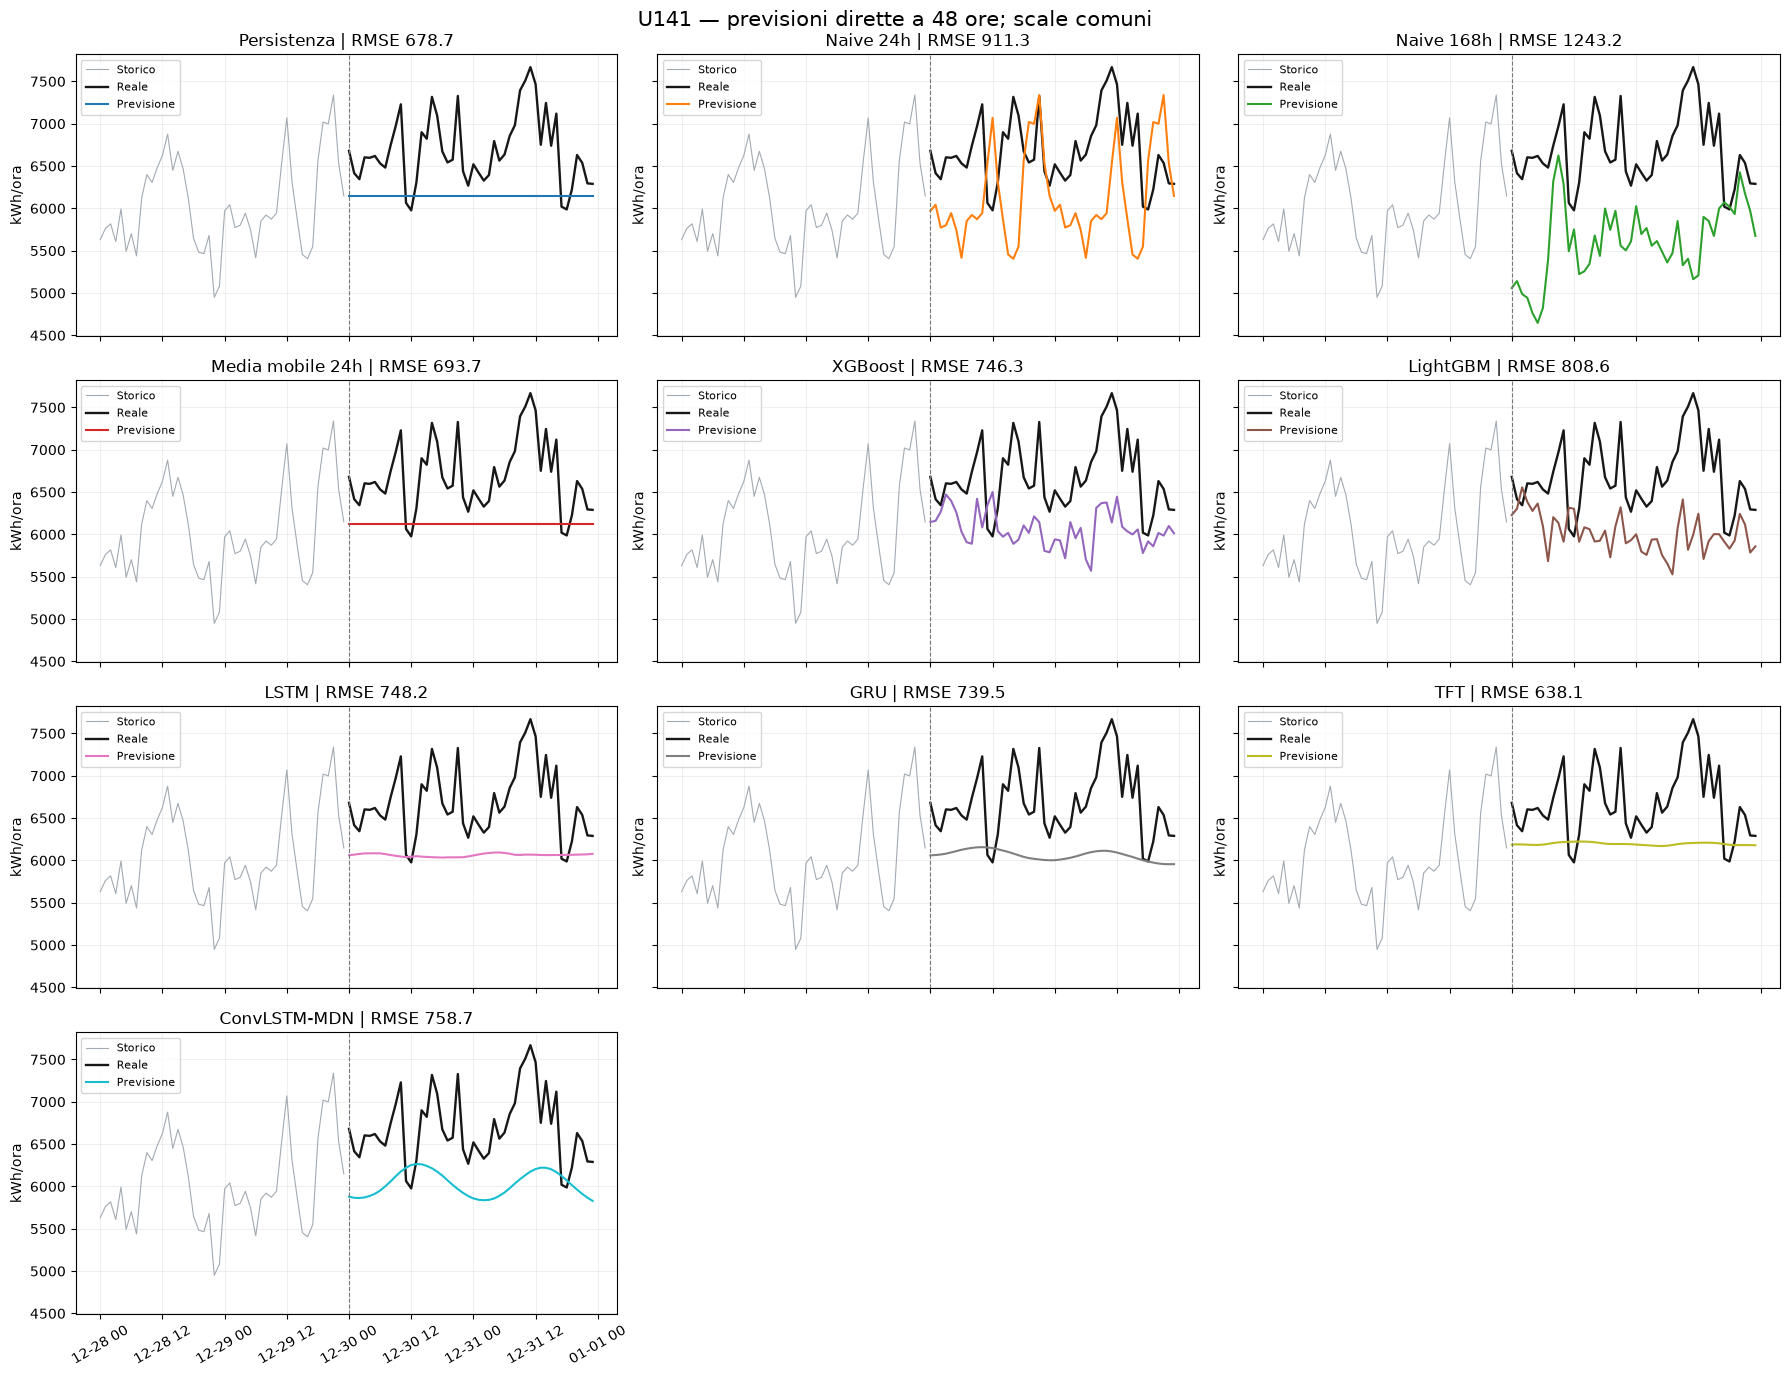

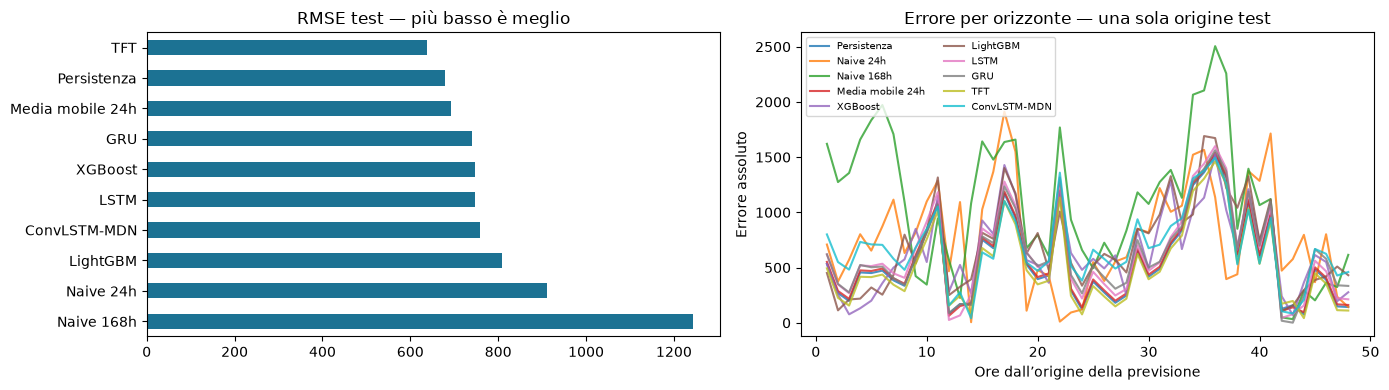

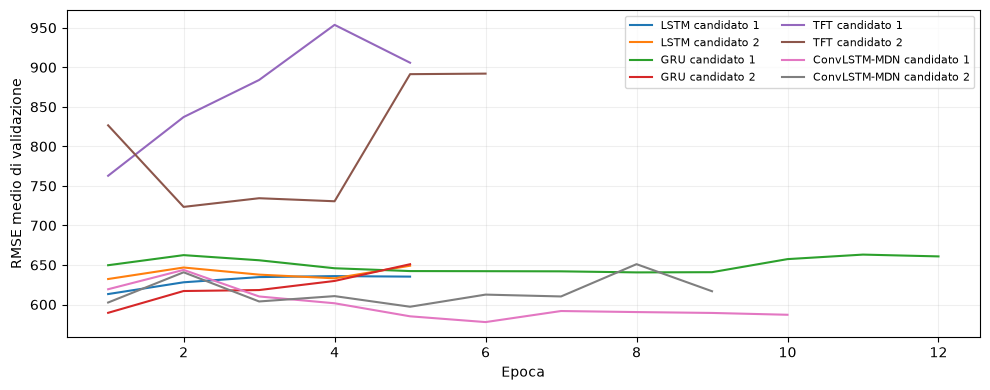

In [9]:
baselines = {
    'Persistenza': np.repeat(train.iloc[-1], H),
    'Naive 24h': np.resize(train.iloc[-24:].to_numpy(), H),
    'Naive 168h': np.resize(train.iloc[-168:].to_numpy(), H),
    'Media mobile 24h': np.repeat(train.iloc[-24:].mean(), H),
}
all_predictions = {name: pd.Series(pred, index=test.index) for name, pred in baselines.items()}
all_predictions.update(predictions)
previsioni = pd.DataFrame(all_predictions, index=test.index)
metrics = {name: scores(test, pred, train) for name, pred in previsioni.items()}
confronto = pd.DataFrame(metrics).T.sort_values('RMSE')
confronto['RMSE validazione'] = pd.Series({name: info['RMSE_val'] for name, info in selection.items()})
confronto['secondi ricerca + refit'] = pd.Series({name: info['secondi'] for name, info in selection.items()})
# Usa le metriche già calcolate: nessun nuovo training.
tabella_sintetica = (
    confronto.loc[:, ['RMSE validazione', 'RMSE', 'MAE', 'MASE', 'R²']]
    .rename(columns={'RMSE': 'RMSE test', 'MAE': 'MAE test'})
    .sort_values('RMSE test')
    .rename_axis('Modello')
    .copy()
)
display(tabella_sintetica.style.format(
    {'RMSE validazione': '{:.2f}', 'RMSE test': '{:.2f}', 'MAE test': '{:.2f}',
     'MASE': '{:.3f}', 'R²': '{:.3f}'},
    na_rep='—'
))
display(pd.concat([test.rename('Reale'), previsioni], axis=1))

names = list(all_predictions)
fig, axes = plt.subplots(int(np.ceil(len(names)/3)), 3, figsize=(18, 3.5*int(np.ceil(len(names)/3))),
                         sharex=True, sharey=True, squeeze=False)
for i, (name, ax) in enumerate(zip(names, axes.flat)):
    ax.plot(train.iloc[-48:], color='#a3aab2', lw=.8, label='Storico')
    ax.plot(test, color='#171717', lw=1.7, label='Reale')
    ax.plot(previsioni[name], color=plt.get_cmap('tab10')(i % 10), lw=1.5, label='Previsione')
    ax.axvline(test.index[0], color='#777777', lw=.8, ls='--')
    ax.set_title(f"{name} | RMSE {confronto.loc[name, 'RMSE']:.1f}")
    ax.set_ylabel('kWh/ora')
    ax.tick_params(axis='x', rotation=30)
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
for ax in list(axes.flat)[len(names):]:
    ax.set_visible(False)
fig.suptitle(f'{USER} — previsioni dirette a {H} ore; scale comuni', fontsize=15)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
confronto['RMSE'].plot.barh(ax=axes[0], color='#1c7293')
axes[0].invert_yaxis()
axes[0].set_title('RMSE test — più basso è meglio')
for name in previsioni:
    axes[1].plot(np.arange(1, H+1), np.abs(previsioni[name].to_numpy()-test.to_numpy()), label=name, alpha=.8)
axes[1].set_xlabel('Ore dall’origine della previsione')
axes[1].set_ylabel('Errore assoluto')
axes[1].set_title('Errore per orizzonte — una sola origine test')
axes[1].legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

if histories:
    fig, ax = plt.subplots(figsize=(10, 4))
    for (name, cid), curve in histories.items():
        ax.plot(curve['epoca'], curve['RMSE_val'], label=f'{name} candidato {cid+1}')
    ax.set_xlabel('Epoca')
    ax.set_ylabel('RMSE medio di validazione')
    ax.legend(fontsize=8, ncol=2)
    ax.grid(alpha=.2)
    fig.tight_layout()
    plt.show()

## 9. Incertezza ConvLSTM-MDN
Calcoliamo i quantili 10% e 90% **dell’intera miscela**, non la somma dei quantili delle componenti. La copertura osservata su 48 ore è una diagnostica esplorativa, non prova di calibrazione. Per confrontare modelli probabilistici in modo affidabile serviranno più origini e metriche dedicate (pinball loss, CRPS).

Copertura osservata banda nominale 80%: 77.1% | ampiezza media: 1738.3 kWh/ora


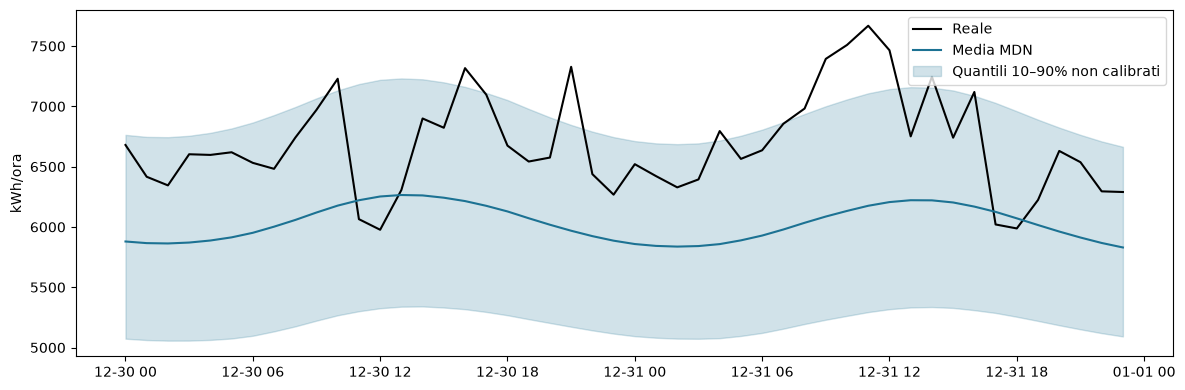

In [10]:
if 'ConvLSTM-MDN' in intervals:
    from scipy.stats import norm
    from scipy.optimize import brentq
    mixture = intervals['ConvLSTM-MDN']
    pi, mu, sigma = mixture['pi'], mixture['mu'], mixture['sigma']
    def mixture_quantile(h, q):
        lo, hi = np.min(mu[h]-12*sigma[h]), np.max(mu[h]+12*sigma[h])
        return brentq(lambda value: np.sum(pi[h]*norm.cdf((value-mu[h])/sigma[h]))-q, lo, hi)
    low = np.array([mixture_quantile(h, .1) for h in range(H)])
    high = np.array([mixture_quantile(h, .9) for h in range(H)])
    assert np.isfinite(low).all() and (low <= high).all()
    banda_mdn = pd.DataFrame({'q10': low, 'media': previsioni['ConvLSTM-MDN'], 'q90': high}, index=test.index)
    coverage = np.mean((test.to_numpy() >= low) & (test.to_numpy() <= high))
    print(f'Copertura osservata banda nominale 80%: {coverage:.1%} | ampiezza media: {np.mean(high-low):.1f} kWh/ora')
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(test, color='black', label='Reale')
    ax.plot(banda_mdn['media'], color='#1c7293', label='Media MDN')
    ax.fill_between(test.index, low, high, color='#1c7293', alpha=.2, label='Quantili 10–90% non calibrati')
    ax.legend()
    ax.set_ylabel('kWh/ora')
    fig.tight_layout()
    plt.show()
else:
    print('Banda non disponibile: ConvLSTM-MDN non eseguito o fallito.')

## 10. Salvataggio facoltativo e limiti
`SAVE_RESULTS=True` salva metriche, previsioni, ricerca e configurazione in una **nuova cartella** con timestamp. Non sovrascrive notebook, CSV o risultati precedenti. Non serializza i pesi dei modelli.

Per una valutazione successiva: più origini esterne walk-forward con tuning interno, più utenti e seed, e una finestra di training più ampia. Se si amplia lo storico, riallineare anche le baseline statistiche prima del confronto. Il TFT e la rete probabilistica sono strumenti esplorativi: maggiore complessità non garantisce minore errore.

Gli snapshot intermedi dipendono da `CHECKPOINT_RESULTS` e vengono salvati anche quando `SAVE_RESULTS=False`; quest’ultimo controlla solo l’esportazione finale in CSV.

In [11]:
if SAVE_RESULTS:
    stamp = pd.Timestamp.now().strftime('%Y%m%d_%H%M%S_%f')
    out_dir = ROOT/'risultati_modelli_avanzati'/f'{USER}_{stamp}'
    out_dir.mkdir(parents=True, exist_ok=False)
    confronto.to_csv(out_dir/'metriche.csv')
    pd.concat([test.rename('Reale'), previsioni], axis=1).to_csv(out_dir/'previsioni.csv', index_label='ora')
    ricerca_parametri.to_csv(out_dir/'ricerca_parametri.csv', index=False)
    if 'ConvLSTM-MDN' in intervals:
        banda_mdn.to_csv(out_dir/'banda_mdn.csv', index_label='ora')
    manifest = dict(user=USER, horizon=H, lookback=LOOKBACK, train_days=TRAIN_DAYS,
                    validation_blocks=VAL_BLOCKS, stride=TRAIN_STRIDE, seed=SEED,
                    train_start=str(train.index[0]), train_end=str(train.index[-1]),
                    test_start=str(test.index[0]), test_end=str(test.index[-1]),
                    device=DEVICE, versions=versions, states=model_status, selected=selection,
                    tree_grid=TREE_GRID, net_grid=NET_GRID, max_epochs=MAX_EPOCHS,
                    patience=PATIENCE, batch_size=BATCH_SIZE)
    (out_dir/'configurazione.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
    print('Salvato in:', out_dir)
else:
    print('Esportazione disattivata. Tutti i risultati sono disponibili nelle variabili del notebook.')

Esportazione disattivata. Tutti i risultati sono disponibili nelle variabili del notebook.


## Riferimenti
- [PyTorch: MPS su macOS](https://docs.pytorch.org/docs/stable/notes/mps.html) e [Apple: PyTorch su Metal](https://developer.apple.com/metal/pytorch/).
- [XGBoost: interfaccia Python/scikit-learn](https://xgboost.readthedocs.io/en/stable/python/python_api.html) e [LightGBM: LGBMRegressor](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMRegressor.html).
- [TFT: implementazione PyTorch Forecasting](https://pytorch-forecasting.readthedocs.io/en/stable/tutorials/stallion.html); [Lim et al.: Temporal Fusion Transformers](https://arxiv.org/abs/1912.09363).
- [Gu e Zhao, 2026: XGBoost/LSTM/BiLSTM su impianto siderurgico](https://www.nature.com/articles/s41598-026-43868-z). Il protocollo del paper è a un passo; qui usiamo output diretto multi-step.
- [Wang et al., 2022: ConvLSTM-MDN per carichi industriali](https://www.frontiersin.org/journals/energy-research/articles/10.3389/fenrg.2022.891680/full). La rete compatta del notebook è un adattamento della famiglia, non una riproduzione esatta del paper.

L’ibrido TFT-LightGBM citato nella rassegna non viene replicato: qui confrontiamo separatamente i due componenti. Una loro combinazione richiederebbe un ulteriore protocollo di training dei residui senza leakage.